# Human tonsil: Fig. 3a-d

RNA, protein and image features lead to the saved 10-domain MELON partition. The same archive contains the method comparisons and modality-removal partitions.

Read the stored outputs below in order. These cells load and plot archived results; they do not preprocess inputs, train models, cluster spots, or fit a new UMAP/t-SNE.

Data: `Published_Data_non_NASH/04_Human_tonsil/`. The sharedoc download link will be added after the archive is uploaded.

In [1]:
from pathlib import Path
import os, sys, json
import numpy as np
import pandas as pd
from IPython.display import display

repo = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Reproduce").is_dir())
sys.path.insert(0, str(repo / "Reproduce"))
from _shared.paper_plots import *
DATA_ROOT = Path(os.environ.get("MELON_PUBLISHED_DATA", repo / "Published_Data_non_NASH"))
DATA = DATA_ROOT / "04_Human_tonsil"
assert DATA.is_dir(), "Place Published_Data_non_NASH beside Reproduce, or set MELON_PUBLISHED_DATA."


## 1. Read the saved multimodal result

The three preprocessed AnnData inputs are stored under `02_model_inputs/MELON/`. The code below starts from the existing embedding and final labels.

In [2]:
embedding = read_indexed(DATA / "03_embeddings/MELON.csv")
labels = read_indexed(DATA / "04_clusters/final_clusters.csv")
embedding = align_embedding(embedding, labels)
assert len(labels) == 4194
display(pd.DataFrame({"spots": [len(labels)], "dimensions": [embedding.shape[1]], "domains": [labels.MELON.nunique()]}))

,spots,dimensions,domains
0,4194,128,10


## 2. Compare the stored partitions — Fig. 3a

Raw cluster IDs remain unchanged. `display_color_mappings.json` supplies the archived color correspondence, so a display color does not become a new cluster label.

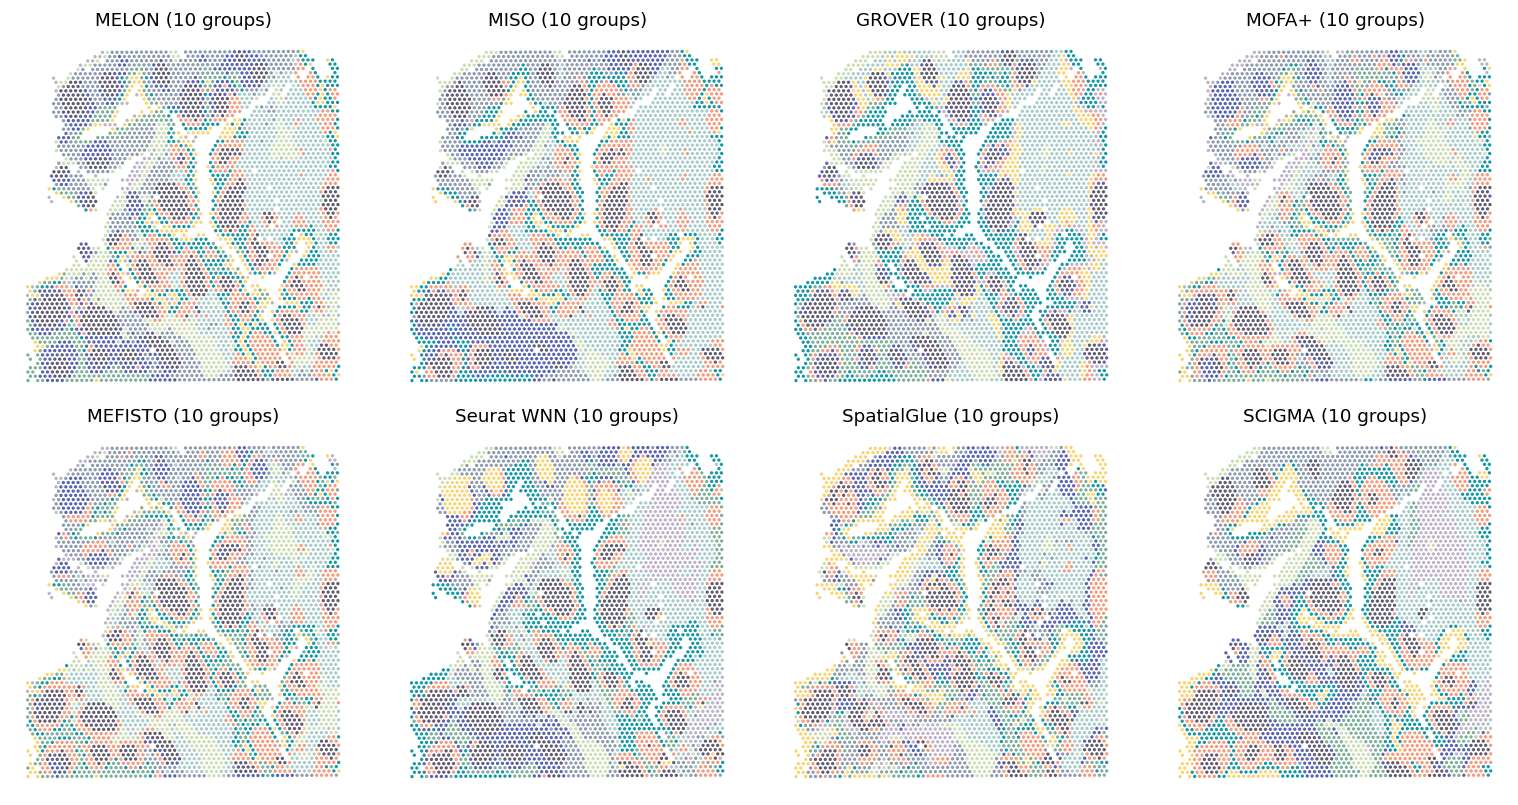

In [3]:
colors = tonsil_colors(DATA)
show(spatial_panels(labels, ["MELON", "MISO", "GROVER", "MOFA+",
                            "MEFISTO", "Seurat WNN", "SpatialGlue", "SCIGMA"], colors=colors))

## 3. Display the saved modality ablations — Fig. 3a

These columns came from independently trained ablation runs. Plot their existing labels; do not simulate an ablation by removing columns from the full embedding.

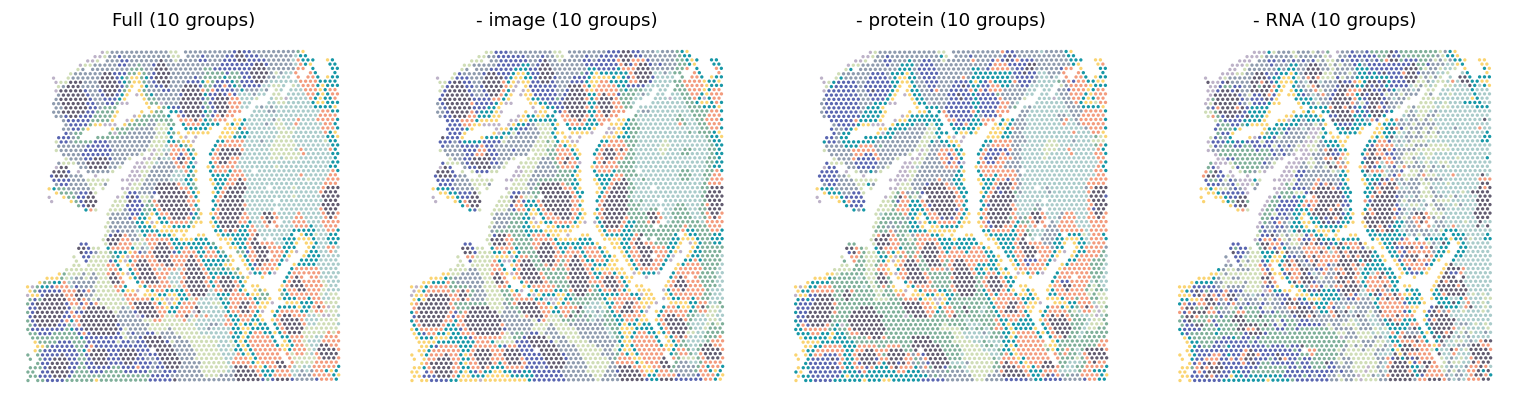

In [4]:
show(spatial_panels(labels, ["Full", "- image", "- protein", "- RNA"], colors=colors, ncols=4))

## Corresponding manuscript figure

The upper half contains the tonsil results: **a**, partitions and modality ablations; **b-c**, protein-marker compartment scores; **d**, RNA-protein abundance and decoder pair activity.

![Manuscript Figure 3](../figures/paper_figure_3.png)

*Original manuscript figure, supplied PDF dated 2026-11-03. The notebook plots above are views of the saved data, not a replacement for this assembled figure.*

## Panel sources

| Panels | Source in this archive |
| --- | --- |
| 3a | `04_clusters/final_clusters.csv`, `display_color_mappings.json`, saved image/features |
| 3b-c | Fixed partitions and protein features are present; the final compartment/paired-bootstrap score tables are separate |
| 3d | RNA/protein inputs and MELON embedding are present; the final decoder pair-activity table is separate |

The archived `saved_settings.json` records 30 epochs, batch size 4096, spatial k = 6 and seed 42. These are the provenance of the stored result shown here; they differ from the generic 100-epoch manuscript-settings runner. No model is rerun in this notebook.